Loaded: /home/alex/snn_for_bts/brain_to_text/model_training/logs/rnn/2026-04-03_17-52-31_037802_rnn_pid114858/checkpoints/validation_only_ctc_analysis_ready.pt
Window: [-10, +10] frames
vowel_boundary_events: 12464
consonant_boundary_events: 28523


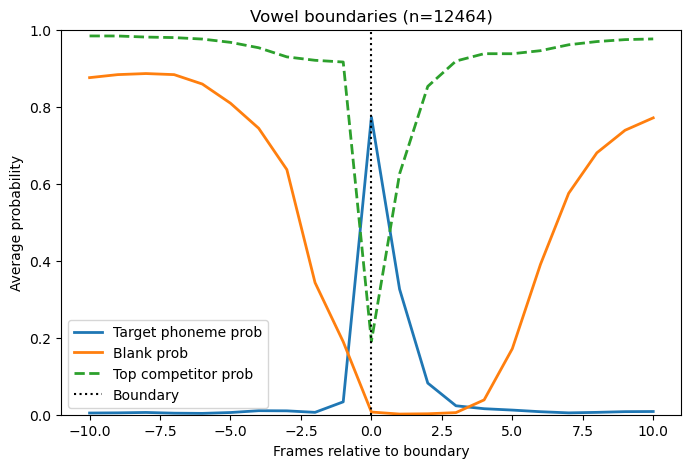

vowel_boundary_events: 12464


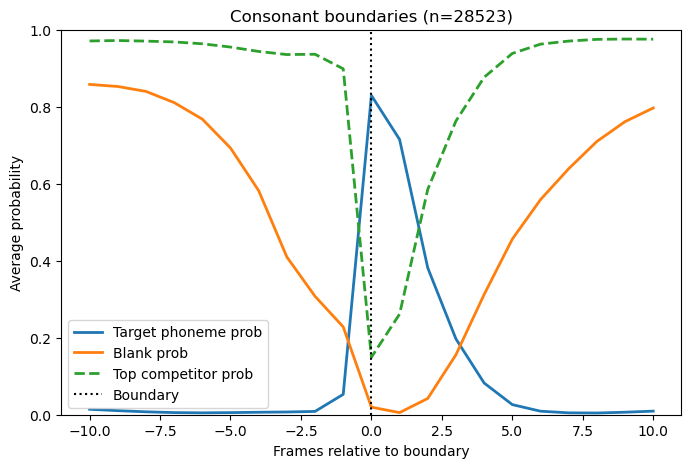

consonant_boundary_events: 28523


In [20]:
from pathlib import Path
import torch
import matplotlib.pyplot as plt

# 0 lag
# "../logs/snn/2026-04-06/2026-04-06_10-43-09_682430_snn_pid649276/checkpoints/validation_only_ctc_analysis_ready.pt"

# 0-7 lags
# ../logs/snn/2026-04-05/2026-04-05_21-56-32_480174_snn_pid559382/checkpoints/validation_only_ctc_analysis_ready.pt"


ENRICHED_PATH = Path(
    "../logs/rnn/2026-04-03_17-52-31_037802_rnn_pid114858/checkpoints/validation_only_ctc_analysis_ready.pt"
).resolve()

WINDOW_BEFORE = 10
WINDOW_AFTER = 10
INCLUDE_TOP_COMPETITOR = True
BLANK_ID = 0

VOWELS = {
    "AA", "AE", "AH", "AO", "AW", "AY",
    "EH", "ER", "EY", "IH", "IY", "OW",
    "OY", "UH", "UW",
}


def phoneme_group_from_id(class_id, vocab):
    token = str(vocab[int(class_id)]).strip()
    if int(class_id) == BLANK_ID or token == "BLANK":
        return "blank"
    if token in VOWELS:
        return "vowel"
    return "consonant"


def collect_boundary_windows(payload, window_before=15, window_after=15, include_top_competitor=True):
    probs = payload["probabilities"]
    input_lengths = payload["input_lengths"].to(torch.long)
    assigned = payload["metadata"]["assigned_target_phoneme"].to(torch.long)
    vocab = payload["phoneme_vocab"]

    window_size = window_before + window_after + 1
    groups = {
        "vowel": {
            "target_prob": [],
            "blank_prob": [],
            "competitor_prob": [],
            "count": 0,
        },
        "consonant": {
            "target_prob": [],
            "blank_prob": [],
            "competitor_prob": [],
            "count": 0,
        },
    }

    for sample_idx in range(probs.shape[0]):
        T = int(input_lengths[sample_idx].item())
        sample_probs = probs[sample_idx, :T]
        sample_assigned = assigned[sample_idx, :T]

        for t in range(1, T):
            prev_id = int(sample_assigned[t - 1].item())
            curr_id = int(sample_assigned[t].item())

            if curr_id == prev_id:
                continue
            if curr_id == BLANK_ID:
                continue

            group = phoneme_group_from_id(curr_id, vocab)
            if group not in groups:
                continue

            start = t - window_before
            end = t + window_after
            if start < 0 or end >= T:
                continue

            window_probs = sample_probs[start : end + 1]

            target_trace = window_probs[:, curr_id]
            blank_trace = window_probs[:, BLANK_ID]

            if include_top_competitor:
                competitor_probs = window_probs.clone()
                competitor_probs[:, curr_id] = -1.0
                competitor_trace = competitor_probs.max(dim=1).values
                groups[group]["competitor_prob"].append(competitor_trace)

            groups[group]["target_prob"].append(target_trace)
            groups[group]["blank_prob"].append(blank_trace)
            groups[group]["count"] += 1

    for group in groups:
        for key in ["target_prob", "blank_prob", "competitor_prob"]:
            if groups[group][key]:
                groups[group][key] = torch.stack(groups[group][key], dim=0)
            else:
                groups[group][key] = torch.empty((0, window_size), dtype=torch.float32)

    return groups


def plot_group_average(groups, group_name, window_before=15, window_after=15, include_top_competitor=True):
    xs = torch.arange(-window_before, window_after + 1)

    target = groups[group_name]["target_prob"]
    blank = groups[group_name]["blank_prob"]
    competitor = groups[group_name]["competitor_prob"]
    count = groups[group_name]["count"]

    plt.figure(figsize=(8, 5))

    if count > 0:
        plt.plot(xs, target.mean(dim=0).cpu(), label="Target phoneme prob", linewidth=2)
        plt.plot(xs, blank.mean(dim=0).cpu(), label="Blank prob", linewidth=2)

        if include_top_competitor and competitor.shape[0] > 0:
            plt.plot(xs, competitor.mean(dim=0).cpu(), label="Top competitor prob", linewidth=2, linestyle="--")

    plt.axvline(0, color="black", linestyle=":", linewidth=1.5, label="Boundary")
    plt.xlabel("Frames relative to boundary")
    plt.ylabel("Average probability")
    plt.title(f"{group_name.capitalize()} boundaries (n={count})")
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.show()

    print(f"{group_name}_boundary_events: {count}")


payload = torch.load(ENRICHED_PATH, map_location="cpu", weights_only=False)
groups = collect_boundary_windows(
    payload,
    window_before=WINDOW_BEFORE,
    window_after=WINDOW_AFTER,
    include_top_competitor=INCLUDE_TOP_COMPETITOR,
)

print(f"Loaded: {ENRICHED_PATH}")
print(f"Window: [-{WINDOW_BEFORE}, +{WINDOW_AFTER}] frames")
print(f"vowel_boundary_events: {groups['vowel']['count']}")
print(f"consonant_boundary_events: {groups['consonant']['count']}")

plot_group_average(
    groups,
    group_name="vowel",
    window_before=WINDOW_BEFORE,
    window_after=WINDOW_AFTER,
    include_top_competitor=INCLUDE_TOP_COMPETITOR,
)

plot_group_average(
    groups,
    group_name="consonant",
    window_before=WINDOW_BEFORE,
    window_after=WINDOW_AFTER,
    include_top_competitor=INCLUDE_TOP_COMPETITOR,
)


Loaded: /home/alex/snn_for_bts/brain_to_text/model_training/logs/rnn/2026-04-03_17-52-31_037802_rnn_pid114858/checkpoints/validation_only_ctc_analysis_ready.pt
frame_entropy_shape: (1426, 593)
Window: [-10, +10] frames
vowel_entropy_boundary_events: 12464
consonant_entropy_boundary_events: 28523


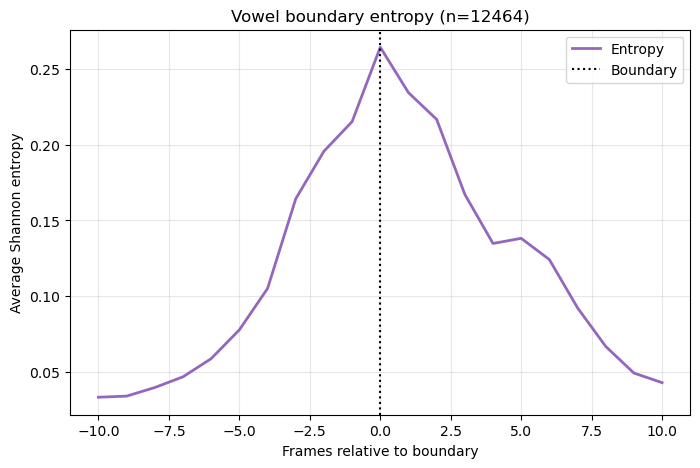

vowel_entropy_boundary_events: 12464


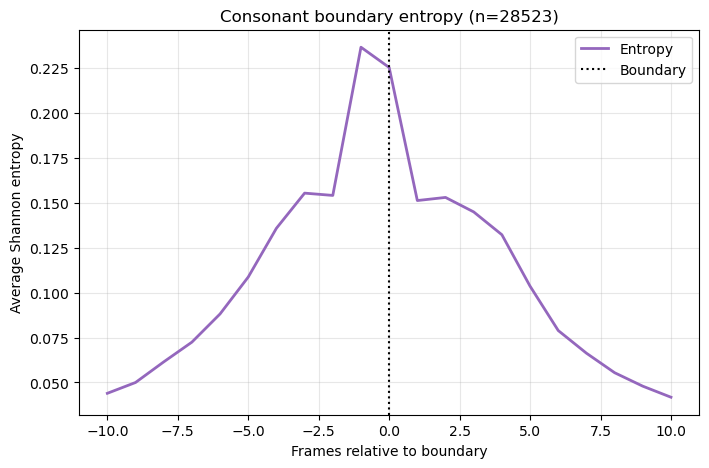

consonant_entropy_boundary_events: 28523


In [22]:
ENTROPY_EPS = 1e-8


def compute_frame_entropy(probabilities, eps=1e-8):
    probs = torch.clamp(probabilities, min=eps)
    return -(probs * torch.log(probs)).sum(dim=-1)


def collect_boundary_entropy_windows(payload, window_before=15, window_after=15, eps=1e-8):
    probabilities = payload["probabilities"]
    input_lengths = payload["input_lengths"].to(torch.long)
    assigned = payload["metadata"]["assigned_target_phoneme"].to(torch.long)
    vocab = payload["phoneme_vocab"]

    frame_entropy = compute_frame_entropy(probabilities, eps=eps)
    window_size = window_before + window_after + 1
    groups = {
        "vowel": {"entropy": [], "count": 0},
        "consonant": {"entropy": [], "count": 0},
    }

    for sample_idx in range(probabilities.shape[0]):
        T = int(input_lengths[sample_idx].item())
        sample_entropy = frame_entropy[sample_idx, :T]
        sample_assigned = assigned[sample_idx, :T]

        for t in range(1, T):
            prev_id = int(sample_assigned[t - 1].item())
            curr_id = int(sample_assigned[t].item())

            if curr_id == prev_id:
                continue
            if curr_id == BLANK_ID:
                continue

            group = phoneme_group_from_id(curr_id, vocab)
            if group not in groups:
                continue

            start = t - window_before
            end = t + window_after
            if start < 0 or end >= T:
                continue

            groups[group]["entropy"].append(sample_entropy[start : end + 1])
            groups[group]["count"] += 1

    for group in groups:
        if groups[group]["entropy"]:
            groups[group]["entropy"] = torch.stack(groups[group]["entropy"], dim=0)
        else:
            groups[group]["entropy"] = torch.empty((0, window_size), dtype=torch.float32)

    return frame_entropy, groups


def plot_entropy_by_boundary_group(groups, group_name, window_before=15, window_after=15):
    xs = torch.arange(-window_before, window_after + 1)
    entropy_windows = groups[group_name]["entropy"]
    count = groups[group_name]["count"]

    plt.figure(figsize=(8, 5))
    if count > 0:
        plt.plot(xs, entropy_windows.mean(dim=0).cpu(), label="Entropy", linewidth=2, color="tab:purple")

    plt.axvline(0, color="black", linestyle=":", linewidth=1.5, label="Boundary")
    plt.xlabel("Frames relative to boundary")
    plt.ylabel("Average Shannon entropy")
    plt.title(f"{group_name.capitalize()} boundary entropy (n={count})")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()

    print(f"{group_name}_entropy_boundary_events: {count}")


if "payload" not in globals():
    payload = torch.load(ENRICHED_PATH, map_location="cpu", weights_only=False)

frame_entropy, entropy_groups = collect_boundary_entropy_windows(
    payload,
    window_before=WINDOW_BEFORE,
    window_after=WINDOW_AFTER,
    eps=ENTROPY_EPS,
)

print(f"Loaded: {ENRICHED_PATH}")
print(f"frame_entropy_shape: {tuple(frame_entropy.shape)}")
print(f"Window: [-{WINDOW_BEFORE}, +{WINDOW_AFTER}] frames")
print(f"vowel_entropy_boundary_events: {entropy_groups['vowel']['count']}")
print(f"consonant_entropy_boundary_events: {entropy_groups['consonant']['count']}")

plot_entropy_by_boundary_group(
    entropy_groups,
    group_name="vowel",
    window_before=WINDOW_BEFORE,
    window_after=WINDOW_AFTER,
)

plot_entropy_by_boundary_group(
    entropy_groups,
    group_name="consonant",
    window_before=WINDOW_BEFORE,
    window_after=WINDOW_AFTER,
)


boundary_overall: n=129044, accuracy=0.9617, error=0.0383
interior_overall: n=44, accuracy=1.0000, error=0.0000
boundary_vowel: n=15257, accuracy=0.8855, error=0.1145
interior_vowel: n=0, accuracy=nan, error=nan
boundary_consonant: n=60429, accuracy=0.9527, error=0.0473
interior_consonant: n=44, accuracy=1.0000, error=0.0000


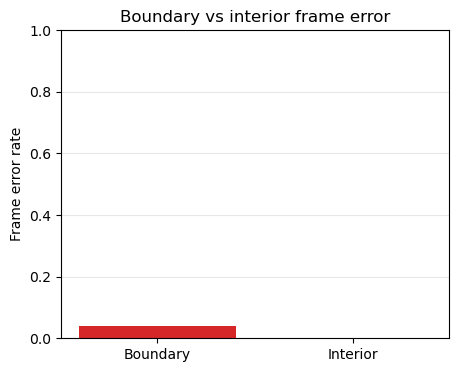

In [19]:
if "payload" not in globals():
    payload = torch.load(ENRICHED_PATH, map_location="cpu", weights_only=False)

metadata = payload["metadata"]
assigned = metadata["assigned_target_phoneme"].to(torch.long)
boundary_mask = metadata["boundary_mask"].to(torch.bool)
interior_mask = metadata["interior_mask"].to(torch.bool)
correctness_mask = metadata["correctness_mask"].to(torch.bool)
input_lengths = payload["input_lengths"].to(torch.long)

valid_mask = torch.arange(assigned.shape[1]).unsqueeze(0) < input_lengths.unsqueeze(1)
boundary_mask = boundary_mask & valid_mask
interior_mask = interior_mask & valid_mask


def compute_accuracy_stats(mask, correctness):
    total = int(mask.sum().item())
    correct = int((correctness & mask).sum().item())
    accuracy = correct / total if total > 0 else float("nan")
    error = 1.0 - accuracy if total > 0 else float("nan")
    return {"count": total, "correct": correct, "accuracy": accuracy, "error": error}


def print_stats(label, stats):
    print(f"{label}: n={stats['count']}, accuracy={stats['accuracy']:.4f}, error={stats['error']:.4f}")


group_id_map = payload.get("group_label_map", {0: "blank", 1: "vowel", 2: "consonant"})
phoneme_group = metadata.get("phoneme_group")
if phoneme_group is not None:
    phoneme_group = phoneme_group.to(torch.long)

overall_boundary = compute_accuracy_stats(boundary_mask, correctness_mask)
overall_interior = compute_accuracy_stats(interior_mask, correctness_mask)

print_stats("boundary_overall", overall_boundary)
print_stats("interior_overall", overall_interior)

if phoneme_group is not None:
    for group_id, group_name in sorted(group_id_map.items()):
        if group_name not in {"vowel", "consonant"}:
            continue
        group_mask = (phoneme_group == int(group_id)) & valid_mask
        print_stats(
            f"boundary_{group_name}",
            compute_accuracy_stats(boundary_mask & group_mask, correctness_mask),
        )
        print_stats(
            f"interior_{group_name}",
            compute_accuracy_stats(interior_mask & group_mask, correctness_mask),
        )

labels = ["Boundary", "Interior"]
errors = [overall_boundary["error"], overall_interior["error"]]

plt.figure(figsize=(5, 4))
plt.bar(labels, errors, color=["tab:red", "tab:blue"])
plt.ylabel("Frame error rate")
plt.title("Boundary vs interior frame error")
plt.ylim(0.0, 1.0)
plt.grid(axis="y", alpha=0.3)
plt.show()
